# Extreme Makeover: Graph Edition, Response Post
Modified versions of a classmate's two visualizations using the scikit-learn Diabetes dataset (`diabetes_visualization_data.csv`). The chart types are unchanged (scatter plot and histogram); only the customization elements were modified.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('diabetes_visualization_data.csv')
n = len(df)
print(n)
df.head()

442


,age_standardized,sex_standardized,bmi_standardized,blood_pressure_standardized,serum_s1,serum_s2,serum_s3,serum_s4,serum_s5,serum_s6,disease_progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## Converting standardized values back to real units
The scikit-learn version of this dataset mean-centers each feature and scales it by its standard deviation times the square root of the number of samples. That makes the axis values (like 0.05) hard to read. Using the mean and population standard deviation of the original raw data published by Efron et al. (age: 48.52 yrs, SD 13.09; BMI: 26.38 kg/m², SD 4.41), the values can be converted back:

`original = mean + standardized * SD * sqrt(n)`

In [2]:
AGE_MEAN, AGE_SD = 48.5181, 13.0942
BMI_MEAN, BMI_SD = 26.3758, 4.4131

df['age_years'] = (AGE_MEAN + df['age_standardized'] * AGE_SD * np.sqrt(n)).round()
df['bmi'] = (BMI_MEAN + df['bmi_standardized'] * BMI_SD * np.sqrt(n)).round(1)
df[['age_years', 'bmi']].describe().round(1)

,age_years,bmi
count,442.0,442.0
mean,48.5,26.4
std,13.1,4.4
min,19.0,18.0
25%,38.2,23.2
50%,50.0,25.7
75%,59.0,29.3
max,79.0,42.2


## Modified Visualization 1: BMI vs. Disease Progression (scatter plot)
Modifications:
1. X-axis converted from standardized values to actual BMI (kg/m²).
2. Shaded background bands and dashed lines at the CDC adult BMI cutoffs of 25 (overweight) and 30 (obesity).
3. Least-squares trend line replaces the free-floating annotation arrow.
4. Text box reporting the Pearson correlation and the average progression in each BMI group.
5. Marker styling (white edges, smaller size) so overlapping points are easier to separate.

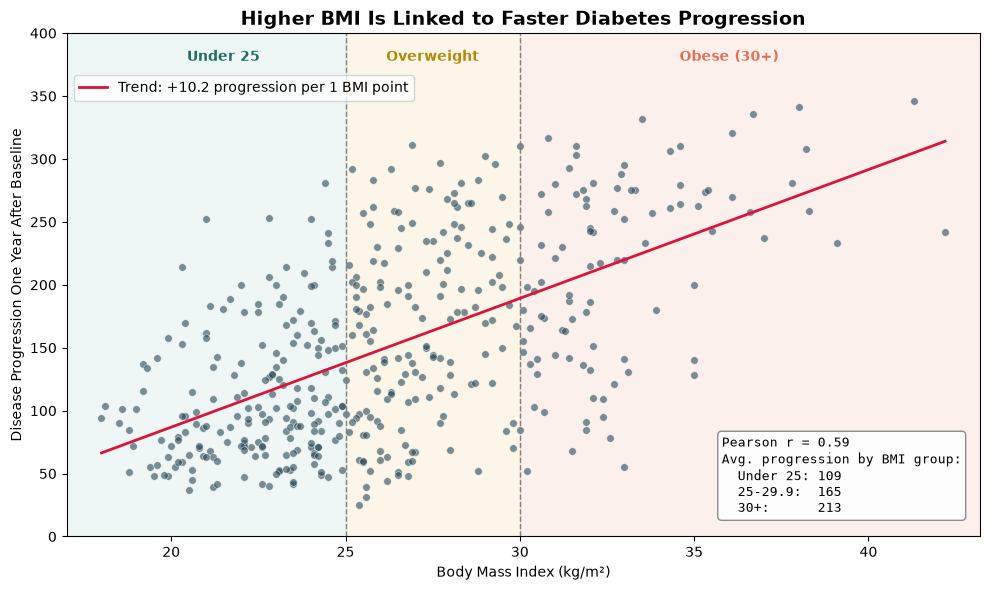

In [3]:
x, y = df['bmi'], df['disease_progression']
r = x.corr(y)
m, b = np.polyfit(x, y, 1)
groups = pd.cut(x, [0, 25, 30, 100], right=False, labels=['Under 25', '25-29.9', '30+'])
grp_means = y.groupby(groups, observed=True).mean()

fig, ax = plt.subplots(figsize=(10, 6))
ax.axvspan(x.min() - 1, 25, color='#2a9d8f', alpha=0.08)
ax.axvspan(25, 30, color='#e9c46a', alpha=0.15)
ax.axvspan(30, x.max() + 1, color='#e76f51', alpha=0.10)
for cut in (25, 30):
    ax.axvline(cut, color='gray', linestyle='--', linewidth=1)
ax.text(21.5, 378, 'Under 25', ha='center', color='#1d6f66', fontweight='bold')
ax.text(27.5, 378, 'Overweight', ha='center', color='#b8860b', fontweight='bold')
ax.text(36, 378, 'Obese (30+)', ha='center', color='#e76f51', fontweight='bold')

ax.scatter(x, y, s=30, color='#264653', alpha=0.6, edgecolors='white', linewidths=0.5)
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, m * xs + b, color='crimson', linewidth=2, label=f'Trend: +{m:.1f} progression per 1 BMI point')

summary = (f'Pearson r = {r:.2f}\n'
           f'Avg. progression by BMI group:\n'
           f'  Under 25: {grp_means.iloc[0]:.0f}\n'
           f'  25-29.9:  {grp_means.iloc[1]:.0f}\n'
           f'  30+:      {grp_means.iloc[2]:.0f}')
ax.text(0.98, 0.04, summary, transform=ax.transAxes, ha='right', va='bottom', multialignment='left', family='monospace', fontsize=9.5,
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray', alpha=0.9))

ax.set_xlim(x.min() - 1, x.max() + 1)
ax.set_ylim(0, 400)
ax.set_title('Higher BMI Is Linked to Faster Diabetes Progression', fontsize=14, fontweight='bold')
ax.set_xlabel('Body Mass Index (kg/m²)')
ax.set_ylabel('Disease Progression One Year After Baseline')
ax.legend(loc='upper left', bbox_to_anchor=(0, 0.93))
plt.tight_layout()
plt.savefig('modified_viz1_bmi_scatter.png', dpi=150)
plt.show()

## Modified Visualization 2: Distribution of Age (histogram)
Modifications:
1. X-axis converted from standardized values to age in years.
2. Bins set to even 5-year intervals (15-80) instead of 12 automatic bins, so each bar has a meaningful age range.
3. Count labels added above each bar.
4. Median line added alongside the mean, with different line styles, to show the slight left skew.
5. New color scheme and removal of the top/right borders for a cleaner look.

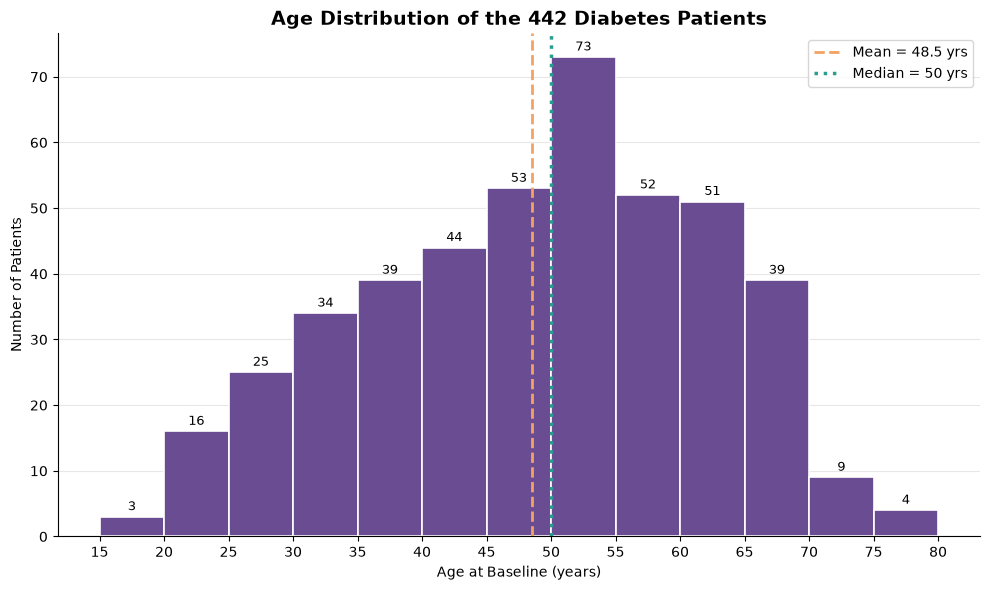

In [4]:
age = df['age_years']
bins = np.arange(15, 85, 5)
mean_age, median_age = age.mean(), age.median()

fig, ax = plt.subplots(figsize=(10, 6))
counts, edges, patches = ax.hist(age, bins=bins, color='#6a4c93', edgecolor='white', linewidth=1.2)
for c, left in zip(counts, edges[:-1]):
    if c > 0:
        ax.text(left + 2.5, c + 1, int(c), ha='center', fontsize=9)

ax.axvline(mean_age, color='#f4a261', linestyle='--', linewidth=2, label=f'Mean = {mean_age:.1f} yrs')
ax.axvline(median_age, color='#2a9d8f', linestyle=':', linewidth=2.5, label=f'Median = {median_age:.0f} yrs')

ax.set_xticks(bins)
ax.set_title(f'Age Distribution of the {n} Diabetes Patients', fontsize=14, fontweight='bold')
ax.set_xlabel('Age at Baseline (years)')
ax.set_ylabel('Number of Patients')
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend()
plt.tight_layout()
plt.savefig('modified_viz2_age_histogram.png', dpi=150)
plt.show()

In [5]:
print('BMI vs progression r =', round(r, 2))
print(grp_means.round(0))
print('Age range:', round(age.min()), '-', round(age.max()), '| mean', round(mean_age, 1), '| median', median_age)
print('Share of patients 40-69:', round(((age >= 40) & (age < 70)).mean() * 100), '%')

BMI vs progression r = 0.59
bmi
Under 25    109.0
25-29.9     165.0
30+         213.0
Name: disease_progression, dtype: float64
Age range: 19 - 79 | mean 48.5 | median 50.0
Share of patients 40-69: 71 %


## References
[1] Scikit-learn Developers, "Diabetes dataset," scikit-learn. [Online]. Available: https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset

[2] B. Efron, T. Hastie, I. Johnstone, and R. Tibshirani, "Least angle regression," Annals of Statistics, vol. 32, no. 2, pp. 407-499, 2004. Raw data: https://www4.stat.ncsu.edu/~boos/var.select/diabetes.html

[3] Centers for Disease Control and Prevention, "Adult BMI categories." [Online]. Available: https://www.cdc.gov/bmi/adult-calculator/bmi-categories.html